# LM4 Lab — Optimization in One Variable

Companion notebook to **From Calculus to Kelly, LM4**. It rebuilds every exhibit and computational example of the module from verified price files and solves the computational practice problems. Each part ends with checks against the numbers printed in the module.

| Part | Rebuilds |
|:--|:--|
| 1 | Total-return series for 0050 (dividends, split, common trading days) |
| 2 | The empirical growth function: Exhibit 1, Exhibit 3, Examples 1 and 3 |
| 3 | Corners: Exhibit 4 and Example 4 |
| 4 | The binary Kelly bet: Exhibit 5, Examples 5 and 6, the envelope derivative in $p$ |
| 5 | Root finding: Exhibit 6, Examples 7 and 8, the two-IRR pitfall |
| 6 | Sensitivity: Exhibits 7 and 8, Examples 9 and 10, sampling error, the Sharpe-3 pitfall |
| 7 | `scipy.optimize`, including the unbounded-search failure of the last Knowledge Check |
| 8 | Practice-problem solutions and an extension exercise |

**Data.** `data/` holds FinMind `TaiwanStockPrice` closes for 0050 and 00631L (2014-10-31 → 2026-10-08, unadjusted, with FinMind's `spread` column) and 0050 cash dividends from `TaiwanStockDividendResult`, retrieved 2026-10-10. 00631L is needed only to reproduce the common trading days used throughout the book.

**Environment.** `uv pip install polars pyarrow numpy scipy matplotlib`. The notebook is written for Polars 1.x and runs unchanged on later versions.

In [1]:
from pathlib import Path
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize_scalar, newton

DATA = Path("data")
pl.Config.set_tbl_rows(30)
pl.Config.set_float_precision(6)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(value, expected, ndigits, label):
    # module numbers are printed at a given precision; reproduce them exactly at that precision
    ok = round(value, ndigits) == round(expected, ndigits)
    print(f"{'ok ' if ok else 'XX '} {label}: {value:.{ndigits + 2}f} (module: {expected})")
    assert ok, label

## Part 1 — Total returns on common trading days

As in LM3: $R_t=(P_t+D_t)/(P_{t-1}/k_t)-1$ with cash dividend $D_t$ on ex-dates and split ratio $k_t$ (0050 4-for-1 on 2025-06-18; 00631L 22-for-1 on 2026-03-31). Returns are computed between consecutive trading days common to both funds, so that every module in the book uses the same 2,902 observations. First, every close is checked against FinMind's own `spread` column.

In [2]:
SPLITS = {"0050": ("2025-06-18", 4), "00631L": ("2026-03-31", 22)}
div = pl.read_csv(DATA / "0050_dividends.csv")

def load_raw(sym):
    df = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    gap = (pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs()
    bad = df.with_columns(gap.alias("gap")).filter(pl.col("gap") > 0.005)
    expected = (set(div["date"]) if sym == "0050" else set()) | {SPLITS[sym][0]}
    unexplained = set(bad["date"]) - expected
    print(f"{sym}: {df.height} rows, spread mismatches {bad.height}, unexplained {sorted(unexplained)}")
    assert not unexplained
    return df

def with_actions(sym):
    df = load_raw(sym)
    sd, k = SPLITS[sym]
    d = (div.select("date", pl.col("cash_dividend").alias("D")) if sym == "0050"
         else pl.DataFrame({"date": [], "D": []}, schema={"date": pl.Utf8, "D": pl.Float64}))
    return (df.join(d, on="date", how="left")
              .with_columns(pl.col("D").fill_null(0.0),
                            pl.when(pl.col("date") == pl.lit(sd)).then(pl.lit(float(k))).otherwise(pl.lit(1.0)).alias("k"))
              .select("date", pl.col("close").alias(f"P_{sym}"), pl.col("D").alias(f"D_{sym}"), pl.col("k").alias(f"k_{sym}")))

both = with_actions("0050").join(with_actions("00631L"), on="date", how="inner").sort("date")
ret = (both.with_columns(
           ((pl.col("P_0050") + pl.col("D_0050")) / (pl.col("P_0050").shift(1) / pl.col("k_0050")) - 1).alias("R"))
           .drop_nulls("R")
           .with_columns(pl.col("date").str.to_date())
           .select("date", "R"))
R = ret["R"].to_numpy()
T = len(R)
YEARS = (ret["date"][-1] - pl.Series(["2014-10-31"]).str.to_date()[0]).days / 365.25   # base close 2014-10-31
A = T / YEARS                                                                            # trading days a year
print(f"T = {T}, {ret['date'][0]} -> {ret['date'][-1]}, {YEARS:.3f} years, A = {A:.2f} trading days a year")
print(f"worst day {ret['date'][int(R.argmin())]}: {R.min():.4%};  best day {ret['date'][int(R.argmax())]}: {R.max():.4%}")
check(T, 2902, 0, "number of returns")
check(A, 243.1, 1, "trading days a year")

0050: 2907 rows, spread mismatches 23, unexplained []
00631L: 2908 rows, spread mismatches 1, unexplained []
T = 2902, 2014-11-03 -> 2026-10-08, 11.937 years, A = 243.11 trading days a year
worst day 2025-04-07: -10.0000%;  best day 2026-07-31: 10.0000%
ok  number of returns: 2902.00 (module: 2902)
ok  trading days a year: 243.109 (module: 243.1)


## Part 2 — The empirical growth function (Section 3)

$\bar g(f)=\frac1T\sum_t\ln(1+fR_t)$ (4.4), $\bar g'(f)=\frac1T\sum_t R_t/(1+fR_t)$ (4.5), $\bar g''(f)=-\frac1T\sum_t R_t^2/(1+fR_t)^2$ (4.6), on the domain $(-1/R_{\max},\,1/\lvert R_{\min}\rvert)$.

In [3]:
def gbar(f, r=R):  return float(np.log1p(f * r).mean())
def dg(f, r=R):    return float((r / (1 + f * r)).mean())
def d2g(f, r=R):   return float(-((r / (1 + f * r)) ** 2).mean())

def domain(r):
    return -1 / r.max(), 1 / -r.min()

def kelly(r, xtol=1e-15):
    lo, hi = domain(r)
    return brentq(lambda f: dg(f, r), lo * (1 - 1e-12), hi * (1 - 1e-12), xtol=xtol)

lo, hi = domain(R)
mu, s2 = R.mean(), R.var()                    # population variance
m2 = (R**2).mean()
f_star = kelly(R)
g_star = gbar(f_star)
f_zero = brentq(gbar, f_star, hi * (1 - 1e-12), xtol=1e-14)
print(f"domain ({lo:.4f}, {hi:.4f});  mu = {mu:.5%}, s = {math.sqrt(s2):.4%}, m2 = {m2:.4e}")
print(f"f* = {f_star:.6f};  g* = {g_star * A:.4%} a year;  zero growth at {f_zero:.4f} = {f_zero / f_star:.3f} f*")
check(f_star, 5.42, 2, "full Kelly f*"); check(g_star * A, 0.5884, 4, "annual growth at f*")
check(f_zero, 9.74, 2, "zero-growth leverage"); check(mu / s2, 5.68, 2, "mu/s^2"); check(mu / m2, 5.652, 3, "mu/(s^2+mu^2)")

domain (-10.0000, 10.0000);  mu = 0.08712%, s = 1.2385%, m2 = 1.5415e-04
f* = 5.421488;  g* = 58.8363% a year;  zero growth at 9.7365 = 1.796 f*
ok  full Kelly f*: 5.4215 (module: 5.42)
ok  annual growth at f*: 0.588363 (module: 0.5884)
ok  zero-growth leverage: 9.7365 (module: 9.74)
ok  mu/s^2: 5.6796 (module: 5.68)
ok  mu/(s^2+mu^2): 5.65164 (module: 5.652)


In [4]:
def max_drawdown(f, r=R):
    w = np.concatenate([[1.0], np.cumprod(1 + f * r)])
    return float((w / np.maximum.accumulate(w) - 1).min())

levels = [("1 (0050 itself)", 1.0), ("2 (exact daily 2x)", 2.0), ("half Kelly", f_star / 2), ("full Kelly", f_star), ("zero growth", f_zero)]
ex1 = pl.DataFrame({
    "leverage": [n for n, _ in levels],
    "f": [f for _, f in levels],
    "annual log growth": [gbar(f) * A for _, f in levels],
    "growth of 1 unit": [math.exp(gbar(f) * T) for _, f in levels],
    "annualized vol": [f * math.sqrt(s2 * A) for _, f in levels],
    "max drawdown": [max_drawdown(f) for _, f in levels],
    "worst day": [f * R.min() for _, f in levels],
})
ex1   # Exhibit 1

leverage,f,annual log growth,growth of 1 unit,annualized vol,max drawdown,worst day
str,f64,f64,f64,f64,f64,f64
"""1 (0050 itself)""",1.000000,0.193082,10.022465,0.193109,-0.339292,-0.100000
"""2 (exact daily 2x)""",2.000000,0.348694,64.223268,0.386217,-0.579160,-0.200000
"""half Kelly""",2.710744,0.436329,182.813806,0.523468,-0.701425,-0.271074
"""full Kelly""",5.421488,0.588363,1122.490157,1.046936,-0.932592,-0.542149
"""zero growth""",9.736503,0.000000,1.000000,1.880202,-0.999916,-0.973650


In [5]:
check(ex1["growth of 1 unit"][3], 1122.5, 1, "growth of 1 unit at f*")
check(ex1["max drawdown"][3], -0.933, 3, "max drawdown at f*")
check(ex1["annual log growth"][2] / ex1["annual log growth"][3], 0.742, 3, "half-Kelly share of growth")
check(ex1["max drawdown"][2], -0.701, 3, "max drawdown at half Kelly")

# Example 1: quadratic rule;  Example 3: the worst day at the zero-growth leverage
print(f"quadratic growth at mu/m2: {mu**2 / (2 * m2) * A:.2%} a year;  one-sd day at f*: {f_star * math.sqrt(s2):.2%}")
print(f"days with |f* R| > 10%: {(np.abs(f_star * R) > 0.10).sum()}")
print(f"worst day at f0: log {math.log1p(f_zero * R.min()):.2f};  at f*: {math.log1p(f_star * R.min()):.2f} of total {g_star * T:.2f}")
check(mu**2 / (2 * m2) * A, 0.5985, 4, "quadratic model's maximal growth")
check(2 * mu / m2, 11.30, 2, "quadratic model's zero")

ok  growth of 1 unit at f*: 1122.490 (module: 1122.5)
ok  max drawdown at f*: -0.93259 (module: -0.933)
ok  half-Kelly share of growth: 0.74160 (module: 0.742)
ok  max drawdown at half Kelly: -0.70143 (module: -0.701)
quadratic growth at mu/m2: 59.85% a year;  one-sd day at f*: 6.71%
days with |f* R| > 10%: 284
worst day at f0: log -3.64;  at f*: -0.78 of total 7.02
ok  quadratic model's maximal growth: 0.598503 (module: 0.5985)
ok  quadratic model's zero: 11.3033 (module: 11.3)


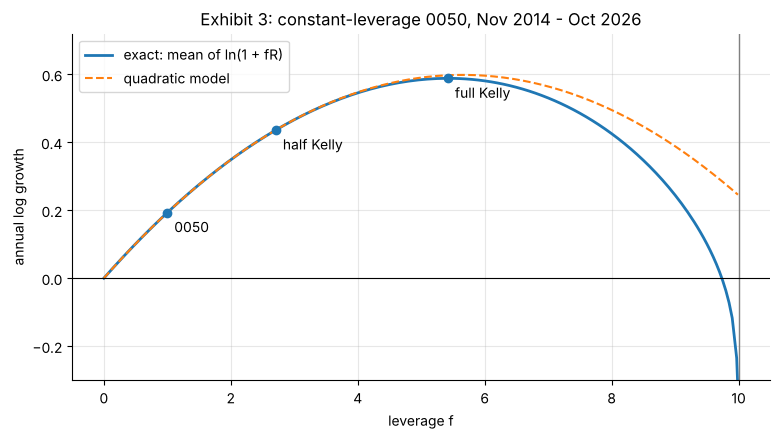

In [6]:
fs_grid = np.concatenate([np.arange(0, 9.95, 0.05), [9.97, 9.99]])
fig, ax = plt.subplots()
ax.plot(fs_grid, [gbar(f) * A for f in fs_grid], lw=2, label="exact: mean of ln(1 + fR)")
ax.plot(fs_grid, (fs_grid * mu - fs_grid**2 * m2 / 2) * A, "--", label="quadratic model")
for f, lab in [(1, "0050"), (f_star / 2, "half Kelly"), (f_star, "full Kelly")]:
    ax.plot(f, gbar(f) * A, "o", color="C0"); ax.annotate(lab, (f, gbar(f) * A), xytext=(5, -14), textcoords="offset points")
ax.axvline(10, color="grey", lw=1); ax.axhline(0, color="black", lw=0.8)
ax.set_ylim(-0.3, 0.72); ax.set_xlabel("leverage f"); ax.set_ylabel("annual log growth")
ax.set_title("Exhibit 3: constant-leverage 0050, Nov 2014 - Oct 2026"); ax.legend(); plt.show()

## Part 3 — Corners (Section 4)

For a concave objective the optimum on $[a,b]$ is the unconstrained optimum clipped to the interval. Exhibit 4 computes the empirical Kelly leverage year by year, each on its own domain.

In [7]:
yearly = []
for y in range(2015, 2026):
    r = ret.filter(pl.col("date").dt.year() == y)["R"].to_numpy()
    fy = kelly(r)
    yearly.append({"year": y, "total return": float(np.prod(1 + r) - 1), "mu (bp/day)": r.mean() * 1e4,
                   "s (%/day)": r.std() * 100, "f* unconstrained": fy, "optimum on [0,2]": min(max(fy, 0.0), 2.0)})
ex4 = pl.DataFrame(yearly)
ex4   # Exhibit 4

year,total return,mu (bp/day),s (%/day),f* unconstrained,"optimum on [0,2]"
i64,f64,f64,f64,f64,f64
2015,-0.063093,-2.126724,1.044064,-1.933218,0.000000
2016,0.196442,7.809605,0.955539,8.370955,2.000000
2017,0.181338,6.951971,0.592457,19.410056,2.000000
2018,-0.049511,-1.502588,1.046024,-1.399963,0.000000
2019,0.335157,12.256514,0.782030,19.732696,2.000000
2020,0.310844,12.123043,1.462384,5.436369,2.000000
2021,0.219709,8.775000,1.125741,6.966230,2.000000
2022,-0.213416,-8.790322,1.388528,-4.459940,0.000000
2023,0.273978,10.534856,0.894305,13.582159,2.000000


In [8]:
check(ex4["f* unconstrained"].min(), -4.46, 2, "lowest yearly f* (2022)")
check(ex4["f* unconstrained"].max(), 19.73, 2, "highest yearly f* (2019)")
assert set(ex4["optimum on [0,2]"].to_list()) == {0.0, 2.0}   # every constrained optimum is a corner

# Example 4: the 2x ceiling and its shadow price
print(f"g(2) = {gbar(2) * A:.2%} a year, x{math.exp(gbar(2) * T):.1f};  shadow price g'(2) = {dg(2) * A:.2%} a year per unit")
print(f"raise the cap to 2.5: first-order {0.5 * dg(2) * A:.2%}, exact {(gbar(2.5) - gbar(2)) * A:.2%}")
check(dg(2) * A, 0.1368, 4, "shadow price of the 2x cap")
check((gbar(2.5) - gbar(2)) * A, 0.0637, 4, "exact gain from 2 to 2.5")

ok  lowest yearly f* (2022): -4.4599 (module: -4.46)
ok  highest yearly f* (2019): 19.7327 (module: 19.73)
g(2) = 34.87% a year, x64.2;  shadow price g'(2) = 13.68% a year per unit
raise the cap to 2.5: first-order 6.84%, exact 6.37%
ok  shadow price of the 2x cap: 0.136789 (module: 0.1368)
ok  exact gain from 2 to 2.5: 0.063656 (module: 0.0637)


## Part 4 — The binary Kelly bet (Section 5)

$g(f)=p\ln(1+fG)+q\ln(1-fL)$ (4.7), $f^*=p/L-q/G=(1/L+1/G)(p-\pi)$ with $\pi=L/(G+L)$ (4.8, 4.10), and $g^*$ from (4.9).

In [9]:
def g_bin(f, p, G, L):  return p * math.log1p(f * G) + (1 - p) * math.log1p(-f * L)
def f_bin(p, G, L):     return p / L - (1 - p) / G
def g_star_bin(p, G, L):
    q = 1 - p
    return p * math.log(p * (G + L) / L) + q * math.log(q * (G + L) / G)

# Example 5: +2% / -1% at p = 0.5
p, G, L = 0.5, 0.02, 0.01
fb = f_bin(p, G, L); gb = g_star_bin(p, G, L)
print(f"f* = {fb:.2f}, risk {fb * L:.0%}, g* = {gb:.4%} per trade (check {g_bin(fb, p, G, L):.6f})")
print(f"0.25x: {g_bin(0.25, p, G, L):.4%} per trade = {g_bin(0.25, p, G, L) / gb:.1%} of g*;  zero growth at "
      f"{brentq(lambda f: g_bin(f, p, G, L), fb, 99.999999):.4f}")
check(gb, 0.05889, 5, "g* of the +2/-1 bet")

# Exhibit 5: the bet as p falls; growth at a fixed 25x
p0 = math.log(1 / 0.75) / math.log(1.5 / 0.75)
rows = []
for pp in (0.60, 0.55, 0.50, 0.45, p0, 0.40, 1 / 3):
    fp = f_bin(pp, G, L)
    rows.append({"p": pp, "f*": fp, "risk": fp * L, "g*": g_star_bin(pp, G, L) if fp > 1e-12 else 0.0, "g at 25x": g_bin(25, pp, G, L)})
print(f"zero growth at fixed 25x: p = {p0:.5f}, where f* = {f_bin(p0, G, L):.2f} and 25/f* = {25 / f_bin(p0, G, L):.2f}")
pl.DataFrame(rows)   # Exhibit 5

f* = 25.00, risk 25%, g* = 5.8892% per trade (check 0.058892)
0.25x: 0.1242% per trade = 2.1% of g*;  zero growth at 50.0000
ok  g* of the +2/-1 bet: 0.0588915 (module: 0.05889)
zero growth at fixed 25x: p = 0.41504, where f* = 12.26 and 25/f* = 2.04


p,f*,risk,g*,g at 25x
f64,f64,f64,f64,f64
0.600000,40.000000,0.400000,0.148342,0.128206
0.550000,32.500000,0.325000,0.098557,0.093549
0.500000,25.000000,0.250000,0.058892,0.058892
0.450000,17.500000,0.175000,0.029243,0.024234
0.415037,12.255625,0.122556,0.014508,-0.000000
0.400000,10.000000,0.100000,0.009712,-0.010423
0.333333,-0.000000,-0.000000,0.000000,-0.056633


In [10]:
# Example 6: breakout rule, +6% / -2%, p = 0.40
p, G, L = 0.40, 0.06, 0.02
fb = f_bin(p, G, L); gb = g_star_bin(p, G, L)
print(f"f* = {fb:.2f}, risk {fb * L:.0%}, p - q/b = {p - (1 - p) / (G / L):.2f}, g* = {gb:.3%}, half Kelly {g_bin(fb / 2, p, G, L):.3%} "
      f"({g_bin(fb / 2, p, G, L) / gb:.1%})")
print(f"five losses: full {1 - (1 - fb * L) ** 5:.1%}, half {1 - (1 - fb * L / 2) ** 5:.1%}, probability {0.6 ** 5:.1%}")
f35 = f_bin(0.35, G, L)
print(f"true p = 0.35: f* = {f35:.2f}, 10x is {fb / f35:.2f} x Kelly, growth {g_bin(10, 0.35, G, L):.3%} vs {g_star_bin(0.35, G, L):.3%} "
      f"({g_bin(10, 0.35, G, L) / g_star_bin(0.35, G, L):.1%})")

# envelope theorem in p, and the relative-entropy identity of the Deep Dive
p, G, L = 0.5, 0.02, 0.01
fb = f_bin(p, G, L); pi = L / (G + L)
print(f"dg*/dp = ln((1+f*G)/(1-f*L)) = {math.log((1 + fb * G) / (1 - fb * L)):.4f};  exact g*(0.51) - g*(0.50) = "
      f"{g_star_bin(0.51, G, L) - g_star_bin(0.50, G, L):.5f}")
print(f"D(p||pi) = {p * math.log(p / pi) + (1 - p) * math.log((1 - p) / (1 - pi)):.6f}  vs  g* = {g_star_bin(p, G, L):.6f}")

f* = 10.00, risk 20%, p - q/b = 0.20, g* = 5.412%, half Kelly 4.173% (77.1%)
five losses: full 67.2%, half 41.0%, probability 7.8%
true p = 0.35: f* = 6.67, 10x is 1.50 x Kelly, growth 1.946% vs 2.475% (78.6%)
dg*/dp = ln((1+f*G)/(1-f*L)) = 0.6931;  exact g*(0.51) - g*(0.50) = 0.00713
D(p||pi) = 0.058892  vs  g* = 0.058892


## Part 5 — Root finding (Section 6)

Bisection halves a sign-change bracket; Newton's method (4.12) jumps to the root of the tangent and squares the error (4.13).

In [11]:
def bisection_trace(phi, a, b, tol):
    out = [(0, a, b)]
    n = 0
    while b - a >= tol:
        n += 1
        m = (a + b) / 2
        a, b = (m, b) if phi(m) > 0 else (a, m)
        out.append((n, a, b))
    return out

def newton_trace(phi, dphi, x0, steps):
    xs = [x0]
    for _ in range(steps):
        xs.append(xs[-1] - phi(xs[-1]) / dphi(xs[-1]))
    return xs

nt = newton_trace(dg, d2g, 0.0, 5)
bt = bisection_trace(dg, 0.0, 10.0, 1e-12)        # dg(0) = mu > 0, dg -> -inf as f -> 10
picks = [0, 1, 2, 3, 4, 10, 20, 30, len(bt) - 1]
ex6 = pl.DataFrame({
    "n": picks,
    "Newton f_n": [nt[n] if n <= 4 else None for n in picks],
    "Newton error": [abs(nt[n] - f_star) if n <= 4 else None for n in picks],
    "bisection width": [bt[n][2] - bt[n][1] for n in picks],
    "bisection midpoint error": [abs((bt[n][1] + bt[n][2]) / 2 - f_star) for n in picks],
})
e = [abs(x - f_star) for x in nt]
C = abs(2 * float(((R / (1 + f_star * R)) ** 3).mean()) / (2 * d2g(f_star)))
print("Newton ratios e(n+1)/e(n)^2:", [round(e[k + 1] / e[k] ** 2, 3) for k in (1, 2, 3)], f" C = {C:.3f}")
print("bisection steps to width < 1e-12:", len(bt) - 1)
ex6   # Exhibit 6

Newton ratios e(n+1)/e(n)^2: [0.046, 0.043, 0.042]  C = 0.043
bisection steps to width < 1e-12: 44


n,Newton f_n,Newton error,bisection width,bisection midpoint error
i64,f64,f64,f64,f64
0,0.000000,5.421488,10.000000,0.421488
1,5.651643,0.230155,5.000000,2.078512
2,5.423915,0.002427,2.500000,0.828512
3,5.421488,0.000000,1.250000,0.203512
4,5.421488,0.000000,0.625000,0.108988
10,null,null,0.009766,0.003317
20,null,null,0.000010,0.000003
30,null,null,0.000000,0.000000
44,null,null,0.000000,0.000000


In [12]:
check(nt[1], 5.651642810, 9, "first Newton step = mu/m2")
check(len(bt) - 1, 44, 0, "bisection steps")

# Example 7: yield to maturity of a 5-year 1.5% annual-coupon bond priced at 97.80
def price(y, c=1.5, n=5, face=100.0):
    t = np.arange(1, n + 1)
    return float((c / (1 + y) ** t).sum() + face / (1 + y) ** n)

def dprice(y, c=1.5, n=5, face=100.0):
    t = np.arange(1, n + 1)
    return float(-(t * c / (1 + y) ** (t + 1)).sum() - n * face / (1 + y) ** (n + 1))

ys = newton_trace(lambda y: price(y) - 97.80, dprice, 0.015, 4)
print("Newton yields:", [f"{y:.7%}" for y in ys], " pricing error after 3 steps:", f"{price(ys[3]) - 97.80:.1e}")
print("bisection steps on [0, 10%] to 1e-10:", len(bisection_trace(lambda y: price(y) - 97.80, 0.0, 0.10, 1e-10)) - 1)
check(ys[3], 0.019663, 6, "yield to maturity")

ok  first Newton step = mu/m2: 5.65164280982 (module: 5.65164281)
ok  bisection steps: 44.00 (module: 44)
Newton yields: ['1.5000000%', '1.9599965%', '1.9662908%', '1.9662919%', '1.9662919%']  pricing error after 3 steps: 1.4e-13
bisection steps on [0, 10%] to 1e-10: 30
ok  yield to maturity: 0.01966292 (module: 0.019663)


In [13]:
# Example 8: truncating the geometric series of the Kelly condition
m1, m3, m4 = mu, (R**3).mean(), (R**4).mean()
roots3 = [x.real for x in np.roots([m3, -m2, m1]) if abs(x.imag) < 1e-12 and lo < x.real < hi]
roots4 = [x.real for x in np.roots([-m4, m3, -m2, m1]) if abs(x.imag) < 1e-12 and lo < x.real < hi]
skew = ((R - mu) ** 3).mean() / s2**1.5; exkurt = ((R - mu) ** 4).mean() / s2**2 - 3
print(f"2 terms {m1 / m2:.3f}  3 terms {roots3}  4 terms {roots4}  exact {f_star:.3f};  skew {skew:.3f}, excess kurtosis {exkurt:.2f}")

# Pitfall: two IRRs and a flat tangent
cf = [-100, 230, -132]
npv = lambda r: sum(x / (1 + r) ** t for t, x in enumerate(cf))
dnpv = lambda r: sum(-t * x / (1 + r) ** (t + 1) for t, x in enumerate(cf))
for r0 in (0.14, 0.15):
    path = newton_trace(npv, dnpv, r0, 12)
    print(f"start {r0:.0%}: " + " -> ".join(f"{x:.2%}" for x in path[:3]) + f" ... {path[-1]:.4%}")

# Newton on 0050's Kelly condition from 199 starting points
worst = 0
for f0 in np.round(np.arange(-9.9, 9.95, 0.1), 1):
    f = f0
    for it in range(60):
        f = f - dg(f) / d2g(f)
        assert lo < f < hi
        if abs(f - f_star) < 1e-12:
            worst = max(worst, it + 1); break
print("Newton converged from all 199 starts; most iterations needed:", worst)

2 terms 5.652  3 terms [np.float64(5.752814632134082)]  4 terms [np.float64(5.464911036046388)]  exact 5.421;  skew 0.037, excess kurtosis 8.12
start 14%: 14.00% -> -1.20% -> 5.18% ... 10.0000%
start 15%: 15.00% -> 72.50% -> 29.86% ... 20.0000%
Newton converged from all 199 starts; most iterations needed: 8


## Part 6 — Sensitivity of the optimum (Section 7)

Quadratic model: $g(\lambda f^*)=[1-(1-\lambda)^2]g^*$ (4.15). Envelope theorem: $V'(\theta)=\partial F/\partial\theta$ at the optimum (4.16).

ok  0050 share at 1.5x Kelly: 0.69119 (module: 0.691)
ok  0050 share at 1.75x Kelly: 0.17948 (module: 0.179)


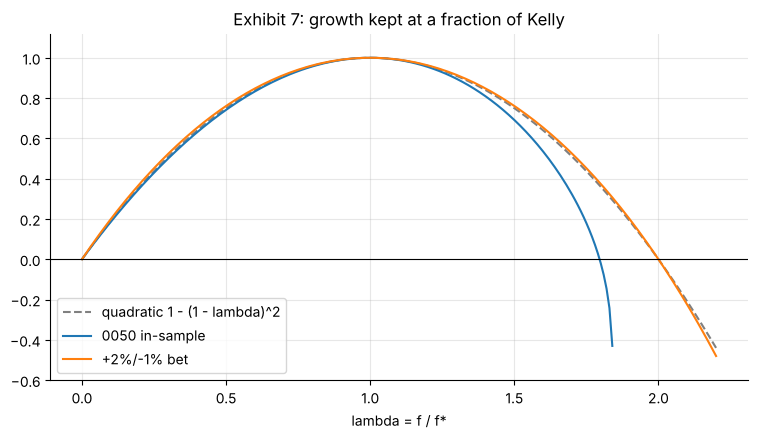

lambda,0050 exact,+2/-1 bet exact,quadratic
f64,f64,f64,f64
0.250000,0.429470,0.452056,0.437500
0.500000,0.741598,0.760824,0.750000
0.750000,0.933772,0.940835,0.937500
0.900000,0.989203,0.990561,0.990000
1.100000,0.988861,0.990561,0.990000
1.250000,0.928256,0.940835,0.937500
1.500000,0.691186,0.760824,0.750000
1.750000,0.179475,0.452056,0.437500


In [14]:
lams = [0.25, 0.5, 0.75, 0.9, 1.1, 1.25, 1.5, 1.75]
ex7 = pl.DataFrame({"lambda": lams}).with_columns(
    pl.Series("0050 exact", [gbar(l * f_star) / g_star for l in lams]),
    pl.Series("+2/-1 bet exact", [g_bin(l * 25, 0.5, 0.02, 0.01) / g_star_bin(0.5, 0.02, 0.01) for l in lams]),
    (1 - (1 - pl.col("lambda")) ** 2).alias("quadratic"),
)
check(gbar(1.5 * f_star) / g_star, 0.691, 3, "0050 share at 1.5x Kelly")
check(gbar(1.75 * f_star) / g_star, 0.179, 3, "0050 share at 1.75x Kelly")
lam_grid = np.linspace(0, 2.2, 221)
fig, ax = plt.subplots()
ax.plot(lam_grid, 1 - (1 - lam_grid) ** 2, "--", color="grey", label="quadratic 1 - (1 - lambda)^2")
ok = lam_grid * f_star < hi * (1 - 1e-9)
ax.plot(lam_grid[ok], [gbar(l * f_star) / g_star for l in lam_grid[ok]], label="0050 in-sample")
ax.plot(lam_grid, [g_bin(l * 25, 0.5, 0.02, 0.01) / g_star_bin(0.5, 0.02, 0.01) for l in lam_grid], label="+2%/-1% bet")
ax.set_ylim(-0.6, 1.12); ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("lambda = f / f*")
ax.set_title("Exhibit 7: growth kept at a fraction of Kelly"); ax.legend(); plt.show()
ex7

In [15]:
# Example 9: half Kelly and the flat-top approximation (4.14)
pred = 0.5 * abs(d2g(f_star)) * A * (f_star / 2) ** 2
print(f"g''(f*) = {d2g(f_star):.4e} a day = {d2g(f_star) * A:.4f} a year;  predicted loss {pred:.1%}, actual {(g_star - gbar(f_star / 2)) * A:.1%}")

# Example 10: financing at rate r per day; envelope derivative 1 - f* at r = 0
print(f"mean of 1/(1 + f* R) = {(1 / (1 + f_star * R)).mean():.12f};  dV/dr = 1 - f* = {1 - f_star:.2f}")
r_d = 0.02 / A
f_r = brentq(lambda f: float(((R - r_d) / (1 + r_d + f * (R - r_d))).mean()), 0, 9.99, xtol=1e-14)
V_r = float(np.log1p(r_d + f_r * (R - r_d)).mean()) * A
V_old = float(np.log1p(r_d + f_star * (R - r_d)).mean()) * A
print(f"2% a year: first-order {(1 - f_star) * 0.02:.2%}, exact {V_r - g_star * A:.2%};  f*(r) = {f_r:.2f}, V = {V_r:.2%}, old f* earns {V_old:.2%}")
check(V_r - g_star * A, -0.0838, 4, "exact fall in maximal growth at 2% financing")

g''(f*) = -1.8041e-04 a day = -0.0439 a year;  predicted loss 16.1%, actual 15.2%
mean of 1/(1 + f* R) = 1.000000000000;  dV/dr = 1 - f* = -4.42
2% a year: first-order -8.84%, exact -8.38%;  f*(r) = 4.96, V = 50.46%, old f* earns 49.99%
ok  exact fall in maximal growth at 2% financing: -0.083793 (module: -0.0838)


SE(mu) = 0.0230% a day, t = 3.79, relative error 26.4%
95% interval for mu: [0.042%, 0.132%]  ->  f = [2.7, 8.6]
  if true f* = 2.7: lambda = 1.98, quadratic share kept 4.5%
  if true f* = 8.6: lambda = 0.63, quadratic share kept 86.2%


shape: (1, 3)
┌──────────┬──────────┬──────────┐
│ min      ┆ max      ┆ last     │
│ ---      ┆ ---      ┆ ---      │
│ f64      ┆ f64      ┆ f64      │
╞══════════╪══════════╪══════════╡
│ 0.941754 ┆ 8.871458 ┆ 6.632173 │
└──────────┴──────────┴──────────┘


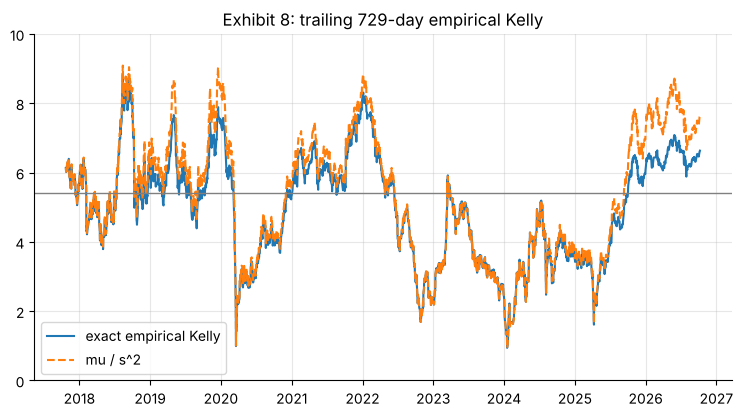

ok  rolling minimum: 0.9418 (module: 0.94)
ok  rolling maximum: 8.8715 (module: 8.87)


In [16]:
# Sampling error of the mean and the implied range of Kelly leverages (preview of LM20 and LM45)
se = math.sqrt(s2) / math.sqrt(T)
lo_mu, hi_mu = mu - 1.96 * se, mu + 1.96 * se
print(f"SE(mu) = {se:.4%} a day, t = {mu / se:.2f}, relative error {se / mu:.1%}")
print(f"95% interval for mu: [{lo_mu:.3%}, {hi_mu:.3%}]  ->  f = [{lo_mu / s2:.1f}, {hi_mu / s2:.1f}]")
for f_true in (lo_mu / s2, hi_mu / s2):
    lam = f_star / f_true
    print(f"  if true f* = {f_true:.1f}: lambda = {lam:.2f}, quadratic share kept {1 - (1 - lam) ** 2:.1%}")

# Exhibit 8: rolling three-year (729-day) empirical Kelly
W = 729
roll = pl.DataFrame({"end": ret["date"][W - 1:],
                     "f*": [kelly(R[e - W:e], xtol=1e-10) for e in range(W, T + 1)],
                     "mu/s2": [R[e - W:e].mean() / R[e - W:e].var() for e in range(W, T + 1)]})
print(roll.select(pl.col("f*").min().alias("min"), pl.col("f*").max().alias("max"), pl.col("f*").last().alias("last")))
fig, ax = plt.subplots()
ax.plot(roll["end"], roll["f*"], label="exact empirical Kelly"); ax.plot(roll["end"], roll["mu/s2"], "--", label="mu / s^2")
ax.axhline(f_star, color="grey", lw=1); ax.set_ylim(0, 10); ax.set_title("Exhibit 8: trailing 729-day empirical Kelly"); ax.legend(); plt.show()
check(roll["f*"].min(), 0.94, 2, "rolling minimum"); check(roll["f*"].max(), 8.87, 2, "rolling maximum")

In [17]:
# Pitfall: "backtest Sharpe 3 -> full Kelly"  (quadratic model, annualized SR and sigma)
SR_bt, sigma = 3.0, 0.15
f_bt = SR_bt / sigma
for SR_true in (1.5, 1.0):
    lam = SR_bt / SR_true
    g = (2 * lam - lam**2) * SR_true**2 / 2
    print(f"true SR {SR_true}: leverage {f_bt:.0f} is {lam:.0f} x Kelly; growth {g:+.2f} a year, wealth factor {math.exp(g):.3f}")
print(f"0050 in-sample: SR = {mu * A / math.sqrt(s2 * A):.2f}, SR/sigma = {mu * A / (s2 * A):.2f}, SR^2/2 = {(mu * A) ** 2 / (s2 * A) / 2:.1%}")

true SR 1.5: leverage 20 is 2 x Kelly; growth +0.00 a year, wealth factor 1.000
true SR 1.0: leverage 20 is 3 x Kelly; growth -1.50 a year, wealth factor 0.223
0050 in-sample: SR = 1.10, SR/sigma = 5.68, SR^2/2 = 60.1%


## Part 7 — `scipy.optimize` (Section 8)

In [18]:
f_b = brentq(dg, 0.0, 0.999 * hi, xtol=1e-14)
f_n = newton(dg, x0=0.0, fprime=d2g, tol=1e-14)
f_m = minimize_scalar(lambda f: -gbar(f), bounds=(0.0, 0.999 * hi), method="bounded").x
print(f"brentq {f_b:.6f}  newton {f_n:.6f}  bounded {f_m:.4f}")

import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                       # log1p of negative numbers outside the domain
    res = minimize_scalar(lambda f: -gbar(f))             # unbounded Brent search: leaves (-10, 10)
print("unbounded search:", res.x, "|", getattr(res, "message", ""))

brentq 5.421488  newton 5.421488  bounded 5.4215
unbounded search: nan | The algorithm terminated without finding a valid bracket. Consider trying different initial points.


## Part 8 — Practice-problem solutions (computational) and an extension

In [19]:
print("PP3 ", f"f*={0.12 / 0.16:.2f}  g*={0.12**2 / 0.32:.4f}  half={0.12 * 0.375 - 0.08 * 0.375**2:.5f}  zero={0.12 / 0.08:.2f}")
print("PP4 ", f"f*={f_bin(0.55, 0.05, 0.05):.2f}")
f6, f6b = f_bin(0.30, 0.08, 0.02), f_bin(0.25, 0.08, 0.02)
print("PP6 ", f"f*={f6:.3f} risk={f6 * 0.02:.1%} g*={g_star_bin(0.30, 0.08, 0.02):.3%}  true p=0.25: f*={f6b:.3f} ratio={f6 / f6b:.2f} "
      f"growth={g_bin(f6, 0.25, 0.08, 0.02):.3%} vs {g_star_bin(0.25, 0.08, 0.02):.3%}")
cf = [-100, 30, 40, 50]
npv = lambda r: sum(x / (1 + r) ** t for t, x in enumerate(cf))
dnpv = lambda r: sum(-t * x / (1 + r) ** (t + 1) for t, x in enumerate(cf))
print("PP7 ", "Newton IRR:", [f"{x:.4%}" for x in newton_trace(npv, dnpv, 0.0, 4)])
print("PP8 ", math.ceil(math.log2(1e8)))
xs = newton_trace(lambda x: x * x - 2, lambda x: 2 * x, 1.0, 4)
es = [abs(x - math.sqrt(2)) for x in xs]
print("PP9 ", [f"{x:.8f}" for x in xs[1:]], [f"{v:.1e}" for v in es[1:]], [round(es[k + 1] / es[k] ** 2, 3) for k in (1, 2)])
print("PP10", f"corner 0.8: g={0.10 * 0.8 - 0.05 * 0.64:.3f}  shadow price={0.10 - 0.10 * 0.8:.3f}")
lam = 2.4 / 0.8
print("PP13", f"f={2.4 / 0.12:.0f}  zero-growth SR={2.4 / 2}  growth at SR 0.8: {(2 * lam - lam**2) * 0.8**2 / 2:.2f} (x{math.exp((2 * lam - lam**2) * 0.8**2 / 2):.3f})")
r20 = ret.filter(pl.col("date") >= pl.lit("2020-01-01").str.to_date())["R"].to_numpy()
print("PP14", f"n={len(r20)}  f*={kelly(r20):.2f}  mu/s2={r20.mean() / r20.var():.2f}")
print("PP15", f"{(0.5 * 0.02 - 0.5 * 0.01) / (0.5 * 0.02**2 + 0.5 * 0.01**2):.1f}")

PP3  f*=0.75  g*=0.0450  half=0.03375  zero=1.50
PP4  f*=2.00
PP6  f*=6.250 risk=12.5% g*=2.817%  true p=0.25: f*=3.125 ratio=2.00 growth=0.122% vs 0.738%
PP7  Newton IRR: ['0.0000%', '7.6923%', '8.8737%', '8.8963%', '8.8963%']
PP8  27
PP9  ['1.50000000', '1.41666667', '1.41421569', '1.41421356'] ['8.6e-02', '2.5e-03', '2.1e-06', '1.6e-12'] [0.333, 0.353]
PP10 corner 0.8: g=0.048  shadow price=0.020
PP13 f=20  zero-growth SR=1.2  growth at SR 0.8: -0.96 (x0.383)
PP14 n=1635  f*=5.38  mu/s2=5.66
PP15 20.0


### Extension: walk-forward Kelly

The module's warning is that an in-sample optimum is not a recommendation. Test it. At each month-end from November 2017, estimate $f^*$ on the trailing 729 days, cap it to $[0,3]$, and hold that leverage for the next month. Compare the realized log growth with constant $f=1$ and with a constant half of the full-sample $f^*$ (which uses future data and is therefore not a fair benchmark either). The scaffold below builds the month-end schedule and the walk-forward leverage; complete the comparison and explain the result with Sections 4 and 7. LM22 (resampling) and LM45 (Kelly under uncertainty) return to this question.

In [20]:
month_end = (ret.with_row_index("i")
                .group_by_dynamic("date", every="1mo").agg(pl.col("i").last())
                .filter(pl.col("i") >= W - 1))
lev = np.full(T, np.nan)
ends = month_end["i"].to_list()
for k, e in enumerate(ends):
    f_hat = min(max(kelly(R[e - W + 1:e + 1], xtol=1e-10), 0.0), 3.0)
    nxt = ends[k + 1] if k + 1 < len(ends) else T - 1
    lev[e + 1:nxt + 1] = f_hat
mask = ~np.isnan(lev)
print(f"walk-forward days: {mask.sum()};  average leverage {np.nanmean(lev):.2f}")
# TODO: compute annual log growth of the walk-forward rule, of f = 1 and of f = f_star / 2 over the same days,
#       e.g. np.log1p(lev[mask] * R[mask]).sum() / (mask.sum() / A), and compare their maximum drawdowns.

walk-forward days: 2167;  average leverage 2.95
